In [2]:
import os

YUNET_MODEL_PATH = "/kaggle/working/face_detection_yunet_2023mar_secound.onnx"

if not os.path.isfile(YUNET_MODEL_PATH):
    !wget -q -O {YUNET_MODEL_PATH} https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx

print("Model exists:", os.path.isfile(YUNET_MODEL_PATH), "-", os.path.getsize(YUNET_MODEL_PATH), "bytes")

Model exists: True - 232589 bytes


In [3]:
# Act 7.1: Face Detection on Cropped Faces (using YuNet)
# Detect the face in each raw GT-DB image and save ONLY the cropped face region,
# removing background so the classifier can no longer overfit to it.

import os
import cv2
import numpy as np

# Path to the YuNet ONNX model (download once, e.g. from opencv_zoo)
YUNET_MODEL_PATH = "/kaggle/working/face_detection_yunet_2023mar_secound.onnx"

RAW_TRAIN_DIR = "/kaggle/input/datasets/winminoolol/gerogiatran-vail/gt_db_train"
RAW_VAL_DIR   = "/kaggle/input/datasets/winminoolol/gerogiatran-vail/gt_db_val"

CROPPED_TRAIN_DIR = "/kaggle/working/gt_db_train_cropped2"
CROPPED_VAL_DIR = "/kaggle/working/gt_db_val_cropped2"

MARGIN = 0.15  # extra padding around the detected box, as a fraction of box size


def crop_faces_from_dir(src_dir, dst_dir, detector):
    os.makedirs(dst_dir, exist_ok=True)
    n_ok, n_fail = 0, 0

    for class_name in sorted(os.listdir(src_dir)):
        class_src = os.path.join(src_dir, class_name)
        if not os.path.isdir(class_src):
            continue

        class_dst = os.path.join(dst_dir, class_name)
        os.makedirs(class_dst, exist_ok=True)

        for fname in sorted(os.listdir(class_src)):
            fpath = os.path.join(class_src, fname)
            img = cv2.imread(fpath)
            if img is None:
                n_fail += 1
                continue

            h, w = img.shape[:2]
            detector.setInputSize((w, h))
            _, faces = detector.detect(img)

            if faces is None or len(faces) == 0:
                print(f"No face found: {fpath}")
                n_fail += 1
                continue

            # Pick the most confident detection (highest score, last column)
            best_face = faces[np.argmax(faces[:, -1])]
            x, y, bw, bh = best_face[:4].astype(int)

            # Add margin and clip to image bounds
            mx, my = int(bw * MARGIN), int(bh * MARGIN)
            x0 = max(x - mx, 0)
            y0 = max(y - my, 0)
            x1 = min(x + bw + mx, w)
            y1 = min(y + bh + my, h)

            face_crop = img[y0:y1, x0:x1]
            if face_crop.size == 0:
                n_fail += 1
                continue

            out_path = os.path.join(class_dst, fname)
            cv2.imwrite(out_path, face_crop)
            n_ok += 1

    print(f"[{src_dir}] Saved {n_ok} cropped faces, {n_fail} failed/skipped -> {dst_dir}")


# Initialize YuNet detector (score/nms thresholds are OpenCV defaults)
face_detector = cv2.FaceDetectorYN.create(
    model=YUNET_MODEL_PATH,
    config="",
    input_size=(320, 320),
    score_threshold=0.6,
    nms_threshold=0.3,
    top_k=5000,
)

crop_faces_from_dir(RAW_TRAIN_DIR, CROPPED_TRAIN_DIR, face_detector)
crop_faces_from_dir(RAW_VAL_DIR, CROPPED_VAL_DIR, face_detector)


[/kaggle/input/datasets/winminoolol/gerogiatran-vail/gt_db_train] Saved 200 cropped faces, 0 failed/skipped -> /kaggle/working/gt_db_train_cropped2
[/kaggle/input/datasets/winminoolol/gerogiatran-vail/gt_db_val] Saved 100 cropped faces, 0 failed/skipped -> /kaggle/working/gt_db_val_cropped2


In [15]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# 1. SETUP & DATA LOADING
IMG_SIZE = (128, 128)
BATCH_SIZE = 16          # best batch size found
LEARNING_RATE = 0.001   # best learning rate found
EPOCHS = 50

train_dir = "/kaggle/working/gt_db_train_cropped2"  # Act 7.1: use cropped faces, not raw images
val_dir = "/kaggle/working/gt_db_val_cropped2"

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=None, shuffle=True
)
val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=None, shuffle=False
)

class_names = train_ds_raw.class_names
num_classes = len(class_names)
print("Classes:", class_names)
print("Number of classes:", num_classes)

train_ds = train_ds_raw.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds_raw.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# 2. MODEL (zoom + contrast augmentation, dropout layers)
final_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # --- Data augmentation (only active during training, ignored at predict time) ---
    layers.RandomZoom(0.2),        # random zoom in/out by up to 20%
    layers.RandomContrast(0.1),  
    layers.RandomFlip("horizontal"),# random contrast change by up to 20%

    # Normalize
    layers.Rescaling(1./255),

    # Conv Layer 1 + Dropout
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.Dropout(0.2),
    layers.MaxPooling2D((2, 2)),

    # Conv Layer 2 + Dropout
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Dropout(0.1),
    layers.MaxPooling2D((2, 2)),

    # Conv Layer 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten
    layers.Flatten(),

    # Dense Layer 1
    layers.Dense(256, activation='relu'),

    # Dense Layer 2 + Dropout
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.1),

    # Output Layer
    layers.Dense(num_classes, activation="softmax")
])

final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",   # labels are integers, not one-hot
    metrics=["accuracy"]
)

print("\n===== MODEL STRUCTURAL SUMMARY =====")
final_model.summary()

# 3. EARLY STOPPING (patience = 5, up to 50 epochs)
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True  # restores weights from the best epoch
)

# 4. TRAIN
print("\nStarting training...")
history = final_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)


Found 200 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
Classes: ['s01', 's02', 's03', 's04', 's05', 's06', 's07', 's08', 's09', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20']
Number of classes: 20

===== MODEL STRUCTURAL SUMMARY =====


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_zoom_5 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_5               │ (None, 128, 128, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_5 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 126, 126, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,551,508 (24.99 MB)

 Trainable params: 6,551,508 (24.99 MB)

 Non-trainable params: 0 (0.00 B)


Starting training...
Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.0400 - loss: 3.0882 - val_accuracy: 0.2300 - val_loss: 2.9827
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.1400 - loss: 2.8916 - val_accuracy: 0.1600 - val_loss: 2.6515
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1500 - loss: 2.5444 - val_accuracy: 0.3700 - val_loss: 2.2320
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2850 - loss: 2.2302 - val_accuracy: 0.5800 - val_loss: 1.9297
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.3450 - loss: 2.0084 - val_accuracy: 0.2700 - val_loss: 2.2663
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.4450 - loss: 1.7172 - val_accuracy: 0.7100 - val_loss: 1.3108
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5950 - loss: 1.3070 - val_accuracy: 0.5100 - val_loss: 1.6031
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7300 - loss: 0.9947 - va

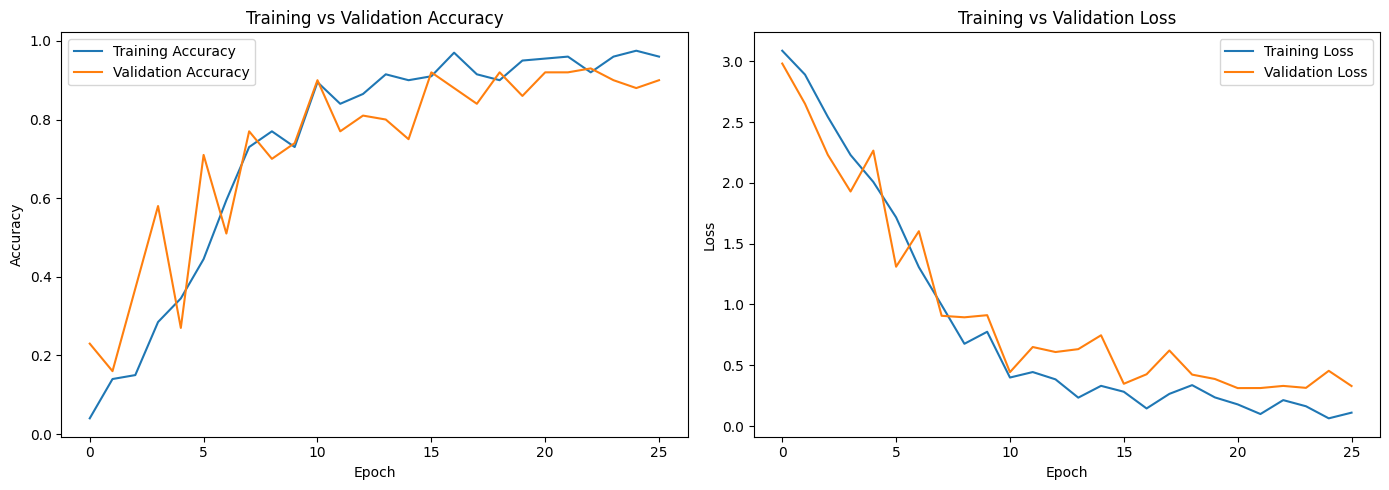

In [16]:


# Set up a figure with two subplots side-by-side
plt.figure(figsize=(14, 5))

# 1. Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

# 2. Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

Enter an image path (or a folder to pick a random image):  /kaggle/working/gt_db_val_cropped2/s11/12.jpg


Selected image: /kaggle/working/gt_db_val_cropped2/s11/12.jpg

INFERENCE RESULT
Image Path   : /kaggle/working/gt_db_val_cropped2/s11/12.jpg
Predicted ID : s11
Accuracy     : 97.62%


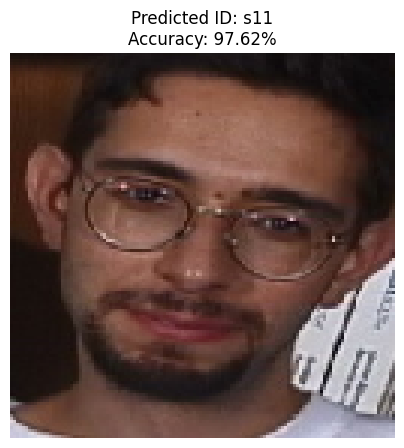

In [19]:
# ============================================================
# IMAGE PREDICTION (uses final_model + class_names from the training cell)
# Input = already-cropped face image
# ============================================================
import os, random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = (128, 128)

# ---- 1. Ask for image path (file or folder) ----
input_image_path = input("Enter an image path (or a folder to pick a random image): ").strip()

if os.path.isdir(input_image_path):
    valid_ext = (".jpg", ".jpeg", ".png", ".bmp")
    files = [f for f in os.listdir(input_image_path) if f.lower().endswith(valid_ext)]
    if not files:
        raise ValueError("No image files found in that folder.")
    input_image_path = os.path.join(input_image_path, random.choice(files))

print("Selected image:", input_image_path)

if not os.path.isfile(input_image_path):
    print("ERROR: Image file does not exist!")
else:
    # ---- 2. Load + resize (same as training: RGB, bilinear, 0-255) ----
    img = tf.keras.utils.load_img(input_image_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_batch = np.expand_dims(img_array, axis=0)  # Rescaling(1/255) is inside the model

    # ---- 3. Predict ----
    predictions = final_model.predict(img_batch, verbose=0)
    
    predicted_index = int(np.argmax(predictions[0]))
    predicted_id = class_names[predicted_index]
    confidence = float(predictions[0][predicted_index])

    print()
    print("======================================")
    print("INFERENCE RESULT")
    print("======================================")
    print("Image Path   :", input_image_path)
    print("Predicted ID :", predicted_id)
    # Changed label to "Accuracy"
    print(f"Accuracy     : {confidence * 100:.2f}%")
    print("======================================")

    # ---- 4. Show image + prediction ----
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    # Changed label to "Accuracy" in the plot title
    plt.title(f"Predicted ID: {predicted_id}\nAccuracy: {confidence * 100:.2f}%")
    plt.show()
